This notebook:
1) starts from simulated market data, given market rate, spot price, dividend yield and a range of strike prices and maturities for option contracts
2) The Fisher information is calculated for every point on the strike-maturity surface 
3) A subset selection is performed based on the D-optimality criterion and the calculated fisher information


In [38]:
import numpy as np
import matplotlib.pyplot as plt

from pricing.heston_cf import price_heston_call
from calibration.heston_calib import calibrate_heston
from calibration.fisher import price_sensitivity, scale_fisher_matrix
from calibration.selection import greedy_d_optimal_selection

from calibration.evaluation_simulation import evaluate_subset

In [7]:
import calibration.fisher
import importlib
importlib.reload(calibration.fisher)

<module 'calibration.fisher' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\calibration\\fisher.py'>

## Simulated market data

In [8]:
true_param = {"v0": 0.04, "kappa": 2.0, "theta": 0.04, "ksi": 0.5, "rho": -0.7}

# Simulated market data
strikes = np.array([80, 90, 95, 100, 105, 110, 120])

maturities = np.array([0.25, 0.5, 1.0, 2.0])

S0 = 100.0
rate = 0.05
dividend_yield = 0.0

# x dollar of noise to market price
noise_std = 0.1

In [9]:
# Simulated prices
market_data_noise = []
rng = np.random.default_rng(5)

for T in maturities:
    for K in strikes:
        true_price = price_heston_call(S0=S0, K=K, v0=true_param["v0"], rate=rate, dividend_yield=dividend_yield,
            kappa=true_param["kappa"], theta=true_param["theta"], ksi=true_param["ksi"], rho=true_param["rho"], T=T)

        noise = rng.normal(0.0, noise_std)
        market_data_noise.append({"strike": K, "maturity": T, "true_price": true_price, "price": true_price + noise})

## 2) Fisher information from simulated market data

In [ ]:
# Calibration
initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

result = calibrate_heston(initial_guess=initial_guess, market_data=market_data_noise, S0=S0, rate=rate, dividend_yield=dividend_yield)
print('Result', result.x)
estimated_params = result.x
parameter_names = ["v0","kappa","theta","ksi","rho"]
true_values = np.array([true_param["v0"],true_param["kappa"],true_param["theta"],true_param["ksi"],true_param["rho"]])

for name, true_value, estimated_value in zip(parameter_names, true_values, estimated_params):
    print(f"{name}: " f"true = {true_value:.6f}, " f"estimated = {estimated_value:.6f}")

Result [ 0.03958027  1.73027317  0.04064707  0.49709981 -0.67182289]
v0: true = 0.040000, estimated = 0.039580
kappa: true = 2.000000, estimated = 1.730273
theta: true = 0.040000, estimated = 0.040647
ksi: true = 0.500000, estimated = 0.497100
rho: true = -0.700000, estimated = -0.671823


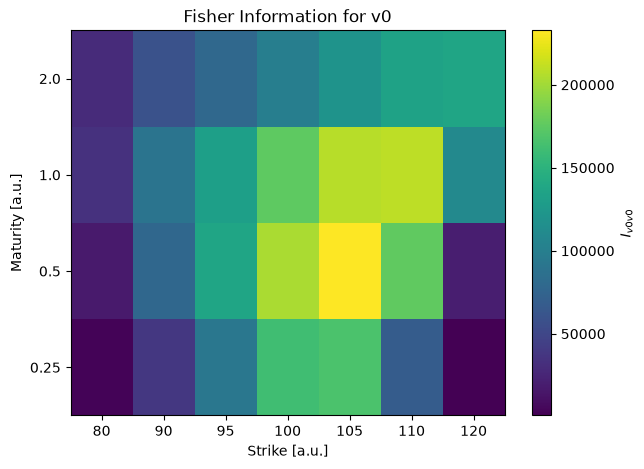

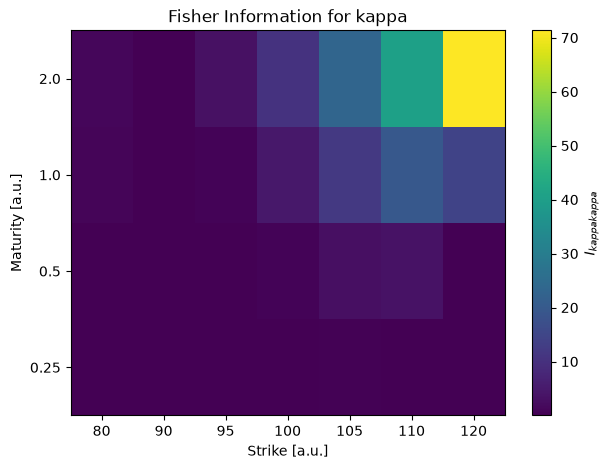

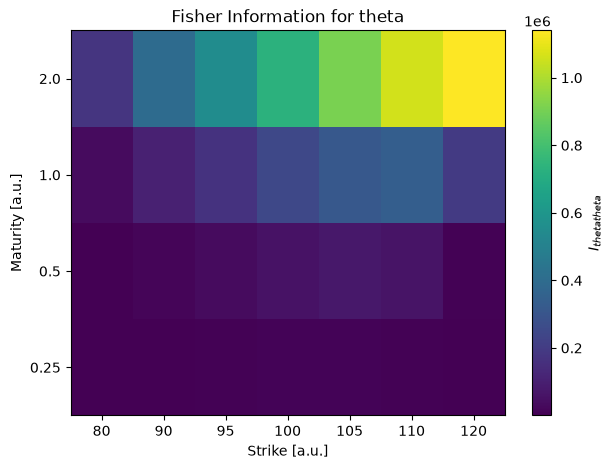

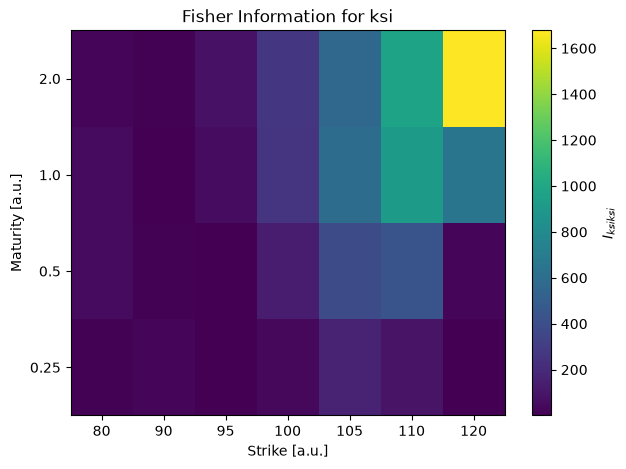

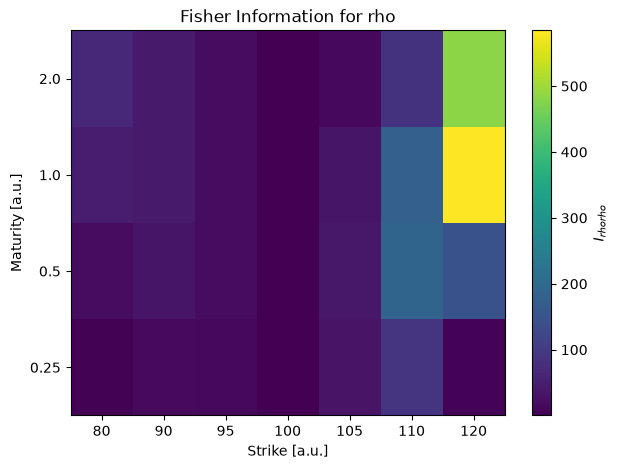

In [ ]:
noise_std_fisher = noise_std

fisher_matrices = {}

for T in maturities:
    for K in strikes:
        jacobian = price_sensitivity(params=estimated_params, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield) 
        noise_std_fisher = noise_std
        jacobian = jacobian.reshape(1, -1)

        fisher_matrices[(T, K)] = (jacobian.T @ jacobian/noise_std_fisher**2)

trace_fisher = {(T, K): np.trace(I) for (T, K), I in fisher_matrices.items()}
trace_matrix = np.array([[trace_fisher[(T, K)] for K in strikes] for T in maturities])

parameter_names = ["v0", "kappa", "theta", "ksi", "rho"]

for j, parameter in enumerate(parameter_names):

    parameter_matrix = np.array([[fisher_matrices[(T, K)][j, j] for K in strikes] for T in maturities])
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(parameter_matrix, aspect="auto", origin="lower")
    ax.set_xticks(np.arange(len(strikes)))
    ax.set_xticklabels(strikes)
    ax.set_yticks(np.arange(len(maturities)))
    ax.set_yticklabels(maturities)
    ax.set_xlabel("Strike [a.u.]")
    ax.set_ylabel("Maturity [a.u.]")
    ax.set_title(f"Fisher Information for {parameter}")

    fig.colorbar(im, ax=ax, label=fr"$I_{{{parameter}{parameter}}}$")
    plt.show()


## 3) Subset selection

[(np.float64(2.0), np.int64(120)), (np.float64(2.0), np.int64(90)), (np.float64(0.5), np.int64(105)), (np.float64(1.0), np.int64(120)), (np.float64(0.25), np.int64(95)), (np.float64(2.0), np.int64(80)), (np.float64(0.25), np.int64(90)), (np.float64(2.0), np.int64(110)), (np.float64(0.5), np.int64(110)), (np.float64(0.5), np.int64(120))]


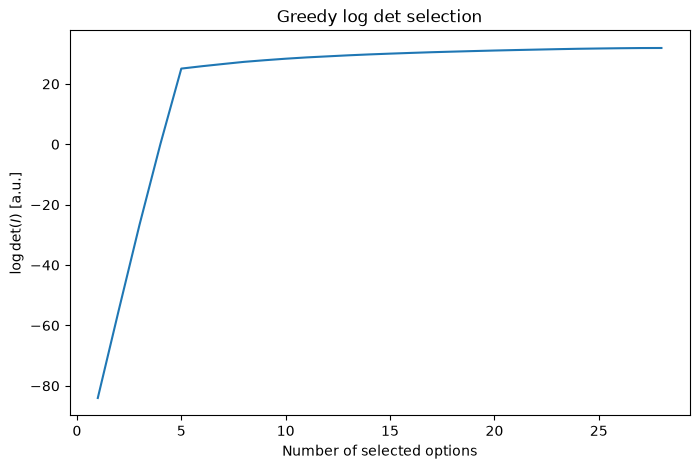

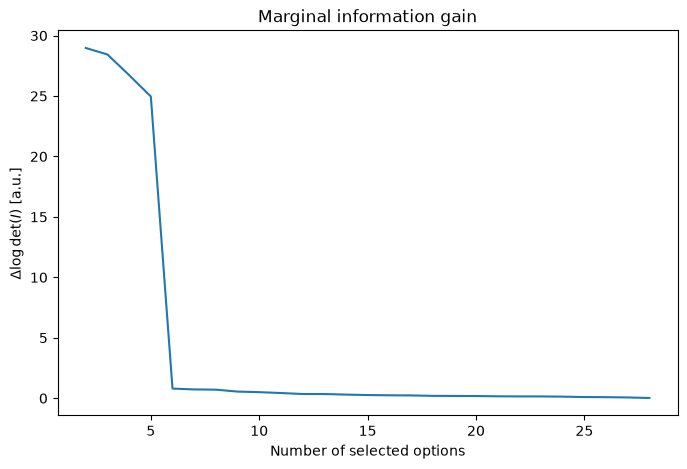

In [14]:
# Selection of most informative option points on strike-maturity surface based on maximising log(det(I)) for 
# sequential selection of option points

# Scale Fisher matrices based on scale of Heston parameters to remove dependence on parameter scale before selecting based on log det
scales = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])
scaled_fisher_matrices = {option: scale_fisher_matrix(I, scales) for option, I in fisher_matrices.items()}

selected, logdet_history = greedy_d_optimal_selection(scaled_fisher_matrices)
print(selected[:10])

n_selected = np.arange(1, len(logdet_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_selected, logdet_history)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\log \det(I)$ [a.u.]")
plt.title("Greedy log det selection")
plt.show()

marginal_gain = np.diff(logdet_history)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(2, len(logdet_history) + 1), marginal_gain)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\Delta \log \det(I)$ [a.u.]")
plt.title("Marginal information gain")
plt.show()

## 4) Using subset to calibrate new model

 5 options | parameter RMSE = 0.120443
 8 options | parameter RMSE = 0.095352
10 options | parameter RMSE = 0.117673
12 options | parameter RMSE = 0.083324
15 options | parameter RMSE = 0.063642
20 options | parameter RMSE = 0.091232
25 options | parameter RMSE = 0.059881
28 options | parameter RMSE = 0.071407


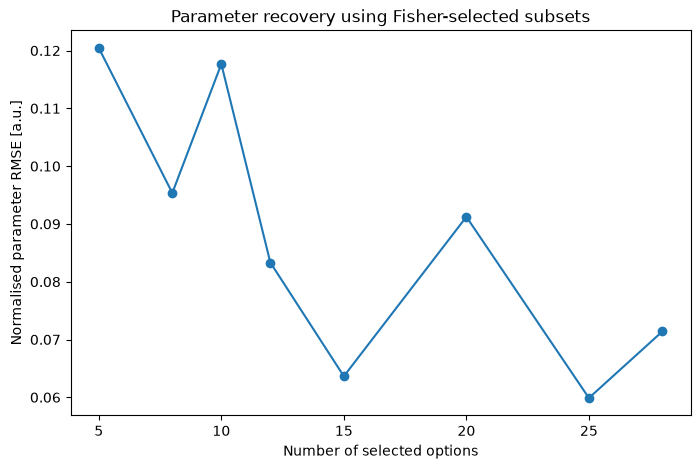

In [ ]:
# Calibration performance as a function of Fisher-selected subset size

subset_sizes = [5, 8, 10, 12, 15, 20, 25, 28]

parameter_names = ["v0", "kappa", "theta", "ksi", "rho"]
scales = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])
calibration_results = []

for n in subset_sizes:
    # Options selected by greedy D-optimal algorithm
    selected_options = set(selected[:n])

    # Keep only market observations in selected subset
    subset_data = [observation for observation in market_data_noise if (observation["maturity"], observation["strike"]) in selected_options]

    # Calibrate using only this subset
    result_subset = calibrate_heston(initial_guess=initial_guess, market_data=subset_data, S0=S0, rate=rate, dividend_yield=dividend_yield)
    estimated_params_subset = result_subset.x

    # Dimensionless parameter RMSE
    parameter_rmse = np.sqrt(np.mean(((estimated_params_subset - true_values) / scales) ** 2))
    calibration_results.append({"n_options": n, "estimated_params": estimated_params_subset, "parameter_rmse": parameter_rmse})

    print(f"{n:2d} options, " f"parameter RMSE = {parameter_rmse:.6f}")

plt.figure(figsize=(8, 5))
plt.plot([r["n_options"] for r in calibration_results],[r["parameter_rmse"] for r in calibration_results], marker="o")
plt.xlabel("Number of selected options")
plt.ylabel("Normalised parameter RMSE [a.u.]")
plt.title("Parameter recovery using Fisher-selected subsets")
plt.show()

### Using subset for out-of-sample pricing

In [39]:
# Generation of new market data

rng_test = np.random.default_rng(123)

test_market_data = []
test_strikes = np.array([82, 87, 92, 97, 102, 107, 112, 117, 125])

test_maturities = np.array([0.20, 0.35, 0.60, 0.80, 1.25, 1.50, 2.50])

for T in test_maturities:
    for K in test_strikes:
        true_price = price_heston_call(S0=S0, K=K, v0=true_param["v0"], rate=rate, dividend_yield=dividend_yield,
            kappa=true_param["kappa"], theta=true_param["theta"], ksi=true_param["ksi"], rho=true_param["rho"], T=T)
        noise = rng_test.normal(0.0, noise_std)
        test_market_data.append({"strike": K, "maturity": T, "true_price": true_price, "price": true_price + noise})

In [ ]:
# Out-of-sample pricing performance

calibration_results = []
scales = np.array([estimated_params[0], estimated_params[1], estimated_params[2], estimated_params[3], 1.0])

for n in subset_sizes:
    selected_options = set(selected[:n])
    result = evaluate_subset(selected_options=selected_options, calibration_data=market_data_noise, test_data=test_market_data, 
        initial_guess=initial_guess, true_params=true_values, scales=scales, S0=S0, rate=rate, 
        dividend_yield=dividend_yield, calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)
    calibration_results.append({"n_options": n, **result})
    print(f"{n:2d} options, "f"parameter RMSE = {result['parameter_rmse']:.6f}, "f"test RMSE = {result['test_rmse']:.6f}")

 5 options, parameter RMSE = 0.120443, test RMSE = 0.054524
 8 options, parameter RMSE = 0.095352, test RMSE = 0.072828
10 options, parameter RMSE = 0.117673, test RMSE = 0.084627
12 options, parameter RMSE = 0.083324, test RMSE = 0.056564
15 options, parameter RMSE = 0.063642, test RMSE = 0.042008
20 options, parameter RMSE = 0.091232, test RMSE = 0.031818
25 options, parameter RMSE = 0.059881, test RMSE = 0.031214
28 options, parameter RMSE = 0.071407, test RMSE = 0.030974


In [ ]:
# Random selection benchmark
n_random_trials = 3

all_options = [(T, K) for T in maturities for K in strikes]

random_results = []

rng_random = np.random.default_rng(42)

for n in subset_sizes:
    for trial in range(n_random_trials):
        random_indices = rng_random.choice(len(all_options), size=n, replace=False)
        random_options = {all_options[i] for i in random_indices}

        result = evaluate_subset(selected_options=random_options, calibration_data=market_data_noise, test_data=test_market_data,
            initial_guess=initial_guess, true_params=true_values, scales=scales, S0=S0, rate=rate, dividend_yield=dividend_yield,
            calibrate_heston=calibrate_heston, price_heston_call=price_heston_call)
        random_results.append({"n_options": n, "trial": trial, **result})
    print(f"Completed {n} options")

# Random-selection results
random_mean = []
random_std = []
for n in subset_sizes:
    errors = [result["test_rmse"] for result in random_results if result["n_options"] == n]
    random_mean.append(np.mean(errors))
    random_std.append(np.std(errors))


Completed 5 options
Completed 8 options
Completed 10 options
Completed 12 options
Completed 15 options
Completed 20 options
Completed 25 options
Completed 28 options


KeyError: 'oos_rmse'

<>:30: SyntaxWarning: invalid escape sequence '\p'
<>:30: SyntaxWarning: invalid escape sequence '\p'
C:\Users\xprp2\AppData\Local\Temp\ipykernel_55360\858633821.py:30: SyntaxWarning: invalid escape sequence '\p'
  plt.fill_between(subset_sizes, np.array(random_mean) - np.array(random_std), np.array(random_mean) + np.array(random_std), alpha=0.2, label=f"Random $\pm$ 1 std")


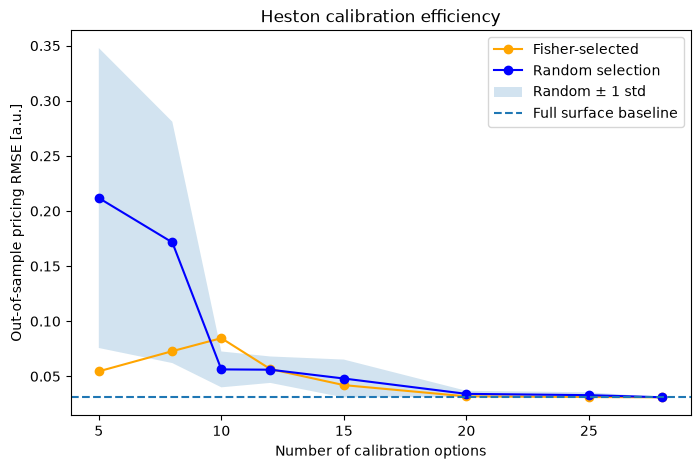

In [ ]:
plt.figure(figsize=(8, 5))
# Fisher-selected
plt.plot(subset_sizes, [result["test_rmse"] for result in calibration_results], marker="o", label="Fisher-selected", color='orange')

# Random selection mean
plt.plot(subset_sizes, random_mean, marker="o", label="Random selection", color='blue')

# Random ± 1 standard deviation
plt.fill_between(subset_sizes, np.array(random_mean) - np.array(random_std), np.array(random_mean) + np.array(random_std), alpha=0.2, label=f"Random $\pm$ 1 std")

# Full-surface baseline
full_surface_rmse = calibration_results[-1]["test_rmse"]
plt.axhline(full_surface_rmse, linestyle="--", label="Full surface baseline")
plt.xlabel("Number of calibration options")
plt.ylabel("Out-of-sample pricing RMSE [a.u.]")
plt.title("Heston calibration efficiency")
plt.legend()
plt.show()

{'n_options': 28, 'surface_rmse': np.float64(3.0595115078927337), 'oos_rmse': np.float64(3.0595115078927337), 'estimated_params': array([ 0.08,  1.  ,  0.08,  0.3 , -0.3 ])}
